---
title: "4.2 · Use with other providers: Bundesliga example"
---

This is part 4.2 of the [User guide](../../usage.qmd), following the [data requirements and preparation guide](../../external-data.qmd). It applies the installed PRESS models to match J03WMX (27 May 2023). Original event and tracking XML are from IDSSE, provided by the Deutsche Fußball Liga (DFL), under CC BY 4.0 [@bassek2025idsse; @idsse-repository]. Download the original data through the [official repository](https://github.com/spoho-datascience/idsse-data).

DataBallPy 0.7.3 is used as an optional external preprocessing tool for alignment and a tracking-based control estimate [@oonk2026databallpy; @databallpy-repository]. PRESS performs the canonical segmentation and context reconstruction. All models are used as fitted. The example demonstrates software interoperability, and predictive generalization to Bundesliga data remains to be assessed. See [input requirements and limitations](../../external-data.qmd).

## Original files and synchronization

Install PRESS with its `io` extra. In a separate Python 3.10 environment install `databallpy==0.7.3` and `pyarrow`. Set `PRESS_IDSSE_DATA` to the downloaded XML directory and `PRESS_SYNC_PYTHON` to that environment's Python executable. `PRESS_IDSSE_OUTPUT` optionally selects a cache/output directory. The bridge reads the original XML, refines alignment and exports tables. The source files remain unchanged.

The adapter applies event revisions and deletions, preserves provider event IDs, and maps players and teams consistently between events and tracking. DataBallPy aligns the action/contact events and estimates the tracked controller. Synchronization categories and football labels are kept apart: a foul, recovery or clearance keeps its own PRESS label whatever generic contact category the synchronizer uses.

Passes, shots, tackles, control starts, fouls and clearances require direct synchronization links to be used by the segmenter. Other events may retain an explicitly labelled clock-interpolated link for audit; these links do not establish possession boundaries. Unlinked and excluded events remain in the event audit. Already aligned bridge outputs can be reused explicitly.


In [1]:
import os
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PRESS import PRESS
from PRESS.io import segment_possessions
from PRESS.visualization import plot_frame, plot_pass_map, plot_bcos
from examples.preprocessing.idsse import prepare_idsse

raw_dir = Path(os.environ["PRESS_IDSSE_DATA"])
output_dir = Path(os.environ.get("PRESS_IDSSE_OUTPUT", "data/external/idsse/J03WMX"))
already_prepared = (output_dir / "aligned/alignment.json").is_file()
tracking, events, players, metadata = prepare_idsse(
    raw_dir, "J03WMX", output_dir,
    synchronize=not already_prepared,
    sync_python=os.environ.get("PRESS_SYNC_PYTHON"),
)
print(metadata["home_team"], "–", metadata["away_team"])
print("Tracking:", len(tracking), "frames at", metadata["fps"], "Hz")
display(events.groupby("sync_method").size().rename("events").to_frame())

1. FC Köln – FC Bayern München
Tracking: 145967 frames at 25.0 Hz


,events
sync_method,
databallpy,1222
excluded,18
interpolated_clock,299
unmatched,68


## Canonical input and custom segmentation {#idsse-segmentation}

DataBallPy's static home/away coordinates already orient the home side towards positive x in both periods. They keep that orientation. The adapter maps provider/player IDs to stable home/away aliases, keeps native pitch metres, differentiates finite contiguous position runs, and reconstructs past score and clock context.

Possession reconstruction and canonical action segmentation are separate steps. The first uses synchronized events and the estimated controller to identify individual control intervals. PRESS then applies its own one-second carry and pass-release convention to those intervals. The [segmentation guide](../setup/possession_and_checkpoint_setup.ipynb) defines the common action, checkpoint and context conventions; the rules below describe how this example obtains their input intervals from IDSSE.

The procedure has four steps, described in the sections below. (1) Possession starts: a start is created by a successful pass reception or by an annotated acquisition of control. (2) Terminal events: from each start, the first eligible terminal event closes the interval. If none is available before a missing tracking range, a period boundary, an eligible stoppage or restart, or an intervening event of another player, the first change of estimated controller bounds the interval and the ending is `unknown`. (3) Pass-link verification: each pass ending is cross-checked against estimated control and flagged with `outcome_verified`. (4) Context labels and canonical checkpoints: PRESS labels each start, assigns the carrier to the interval and constructs the canonical actions and checkpoints.

### Possession starts {#idsse-possession-starts}

This example sets `include_unannotated_starts=False`. The following rules determine starts:

- **Successful pass reception.** After a synchronized successful release, take the identified receiver and the receiver's next synchronized actor event in the same period. The start is the first frame after the release, up to and including the frame of that event, in which the estimated control belongs to the receiver. If the receiver is not in control within this window, the frame immediately before that event is used as the start when the observed ball–receiver distance there is at most 1.5 m (`reception_fallback_max_distance`); this candidate must exist in the same period and strictly follow the release. If the receiver is not identified, has no later synchronized event, or neither control nor the fallback candidate is found, no reception start is created.
- **Annotated acquisition of control.** A synchronized `BallClaiming` establishes a start at the event's synchronized frame for its identified player, subject to the overlap reconciliation below. `Type="InterceptedBall"` supplies `pass_interception`; a generic `Type="BallClaimed"` supplies `recovery`. The identified player starts the interval whichever player the control estimator identifies at the exact contact frame. A won `TacklingGame` is a terminal event and creates no start.

Receptions use observed control or the distance-checked fallback candidate; control acquisitions use the source annotation. No other source creates a start. The optional `include_unannotated_starts=True` also admits tracking-only starts and opponent controls after failed passes, and a reception search without a later receiver event then extends to the end of the period; it is not used here.

Intervals are constructed chronologically without overlap. When a recovery/interception start falls inside the preceding accepted interval, compare its source event with that interval's terminal event. Reconcile the overlap only if the preceding interval ends in a tackle loss, the incoming player is that tackle's winner on the opposing team, and the named loser, if available, is the outgoing carrier. The recovery/interception and tackle must be adjacent relevant events: no intervening pass, shot, tackle, acquisition of control, foul, clearance, stoppage or restart may separate them. Both controls must remain in the same period.

For a coherent pair, retain the outgoing end **at the synchronized tackle frame** and move the incoming start **to the following observed frame**. That frame must exist in the same period. This resolves the small timing disagreement without assigning one frame to two carriers. The report's `overlap_reconciliations` records the original and aligned start frames and supporting event IDs; the interval retains `original_frame_start` and `start_reconciled_with_event_id`. An overlap without this support is recorded in `overlapping_start_annotations` and does not create another interval. No general time-tolerance rule shifts unrelated events.

The returned tracking retains the estimator's original controller as `estimated_player_possession`. Within each reconstructed interval, `player_possession` names that interval's carrier, so its checkpoints and frame-level state use the same player. Attacking direction and score difference remain relative to that carrier's team. This assignment follows the event-supported interval and leaves player and ball positions unchanged.

### Terminal events and outcomes {#idsse-terminal-events}

For each accepted start, search forward within the same period for the first eligible terminal event. An identified ending is assigned exactly to that event's synchronized frame; the individual interval includes both its start and end frames. Passes, shots, fouls suffered and clearances must name the current carrier. A won tackle has a separate winner rule:

| IDSSE annotation | PRESS ending and interpretation |
|---|---|
| `Play` by the carrier | `pass`, with the provider's mapped success/failure annotation. The link is verified as described [below](#idsse-pass-verification). |
| `TacklingGame` with `WinnerResult="ballClaimed"` or `"ballcontactSucceeded"`, and an identified winner different from the carrier | `possession_loss`. The annotated winner determines the loss, whether or not the tracked controller changes or an opponent possession follows. The explicitly named loser can be a player other than the carrier. `PossessionChange` is retained for audit only. A duel won by the carrier is not a loss. |
| `TacklingGame` with `WinnerResult="fouled"`, or an eligible explicit `Foul`, naming the carrier as the fouled player | `foul_suffered`, a non-loss ending. A contact and the following decision for the same fouled player and fouler are linked and counted once. Handballs are excluded. A foul terminates the interval only with a direct synchronization link. |
| `OtherBallAction` by the carrier with `DefensiveClearance="true"` | `clearance`, a non-loss ending outside the terminal pass/carry actions. Only clearance-qualified `OtherBallAction` records terminate possession. The clearance must have a direct synchronization link. |
| `ShotAtGoal` by the carrier | `shot`, kept as an identified ending and excluded from the fitted pass–carry outcome cohort. |

A synchronized terminal annotation can close an interval even when the control estimator changes player earlier. It stops at a missing tracking range, a period boundary, an eligible stoppage/restart, or an intervening pass, shot, foul or clearance attributed to another player. If no eligible terminal event is available before these limits, the first change to another estimated controller also bounds the interval. The ending is then `unknown` and remains distinct from a verified loss.

For a lost tackle, `frame_end` is the tackle frame. When no eligible terminal event identifies the end, the interval ends at the frame immediately before the limit that interrupts it, or at the last available frame when the period simply ends, and the ending remains `unknown`. The checkpoint of the final failed carry precedes `frame_end`: it is the start of the last canonical one-second attempt.

### Pass-link verification {#idsse-pass-verification}

The pass annotation and its tracking cross-check are stored separately. `pass_outcome` retains the mapped provider result: `successful`, `unsuccessful` or `unknown`. Both IDSSE success annotations, `Evaluation="successful"` and `Evaluation="successfullyCompleted"`, map to `successful`; missing or unrecognized success annotations remain `unknown`. A missing recipient leaves this known outcome unchanged and prevents receiver-link verification. For `outcome_verified=True`, the first different estimated controller after release, within the same period, must be the identified receiver for a successful pass, or an opponent for a failed pass. A known provider result is retained when this check fails, but the interval is marked `outcome_verified=False`. Thus an unverified link can reflect a disagreement with estimated control; the source outcome can still be known.

The reception search used to create the next possession and the first-different-controller check used to verify the outgoing pass are distinct operations. An intervening estimated touch can fail the latter even if the identified receiver is subsequently found. The example below selects an interval with a verified completed pass.

### Context labels and canonical checkpoints {#idsse-context-checkpoints}

For a successful reception, the preceding pass's restart qualifier gives `pass_reception`, `throw_in_reception`, `corner_reception`, `free_kick_reception` or `goal_kick_reception`. An unavailable or unsupported qualifier gives `unknown`. Direct `BallClaiming` starts use the interception/recovery labels above; the restart origin is read from annotations only. These labels use the existing fitted vocabularies. The general rule for `previous_action` is unchanged: the start type before one complete second, then `ball_drive`.

The code passes tracking, individual intervals and metadata to `PRESS`, without an externally supplied action table. PRESS constructs the canonical actions and checkpoints at initialization. Complete successful carries supply one-second blocks; a pass supplies a release checkpoint; a direct loss supplies the final failed carry even below one second. Fouls and clearances retain preceding complete carries but supply no terminal pass/carry checkpoint. The [common segmentation guide](../setup/possession_and_checkpoint_setup.ipynb#canonical-checkpoints) covers micropossessions, partial tails and optional snapshots in detail.

These intervals are event-supported estimates, distinct from annotated SkillCorner possessions. The event audit, source event IDs, verification flags and segmentation report allow the reconstructed boundaries to be inspected separately from model predictions.


In [2]:
print("Player sample")
display(players[["player_id", "source_player_id", "full_name", "team_id"]].head())
display(events[["event_id", "event_type", "player_id", "receiver_player_id",
                "is_successful", "restart_type", "frame", "sync_method"]].head())
tracking, individuals, _, report = segment_possessions(
    tracking, events, fps=metadata["fps"], match_id=metadata["match_id"],
    include_unannotated_starts=False,  # Annotated receptions and BallClaiming starts.
    reception_fallback_max_distance=1.5,  # Metres, for missed quick touches only.
)
press = PRESS(
    tracking, player_possessions_data=individuals,
    fps=metadata["fps"], match_id=metadata["match_id"], player_metadata=players,
    pitch_length=metadata["pitch_length"], pitch_width=metadata["pitch_width"],
)
print("Individual controls:", report["n_individual_possessions"])
print("Unverified outcomes:", report["n_unverified_outcomes"])

Player sample
Individual controls: 811
Unverified outcomes: 75


,player_id,source_player_id,full_name,team_id
0,away_27,DFL-OBJ-0002DR,Yann Sommer,away
2,away_13,DFL-OBJ-0000RP,Eric Maxim Choupo-Moting,away
3,away_25,DFL-OBJ-0000IA,Thomas Müller,away
5,away_8,DFL-OBJ-000191,Leon Christoph Goretzka,away
7,away_7,DFL-OBJ-0027G6,Serge David Gnabry,away


,event_id,event_type,player_id,receiver_player_id,is_successful,restart_type,frame,sync_method
0,18226500000006,pass,away_7,away_2,True,kick_off,10000,databallpy
1,18226500000007,pass,away_2,NaN,False,open_play,10042,databallpy
2,18226500000008,pass,home_2,away_2,False,throw_in,10426,databallpy
3,18226500000009,tackle,away_2,NaN,True,unknown,10518,databallpy
4,18226500000010,unknown,away_2,NaN,<NA>,unknown,10524,interpolated_clock


In [3]:
possessions = press.get_player_possessions()
canonical_actions = press.get_actions()
display(possessions.groupby(["start_type", "end_type"]).size().rename("possessions").to_frame())
display(canonical_actions.groupby("action").size().rename("actions").to_frame())

possessions
start_type          end_type                    
corner_reception    pass                       2
                    shot                       1
free_kick_reception pass                      14
                    unknown                    1
goal_kick_reception pass                      12
pass_interception   foul_suffered              1
                    pass                      13
                    possession_loss            3
                    unknown                    1
pass_reception      clearance                  4
                    foul_suffered              7
                    pass                     640
                    possession_loss           32
                    shot                      12
                    unknown                   16
recovery            foul_suffered              1
                    pass                       8
                    possession_loss            2
throw_in_reception  pass                      27
                    possession_loss            4
                    shot                       1
                    unknown                    3
unknown             pass                       6

,actions
action,
ball_drive,1137
pass,722


## One observed possession

Select an outfield reception followed by a verified completed pass, with at least two whole seconds of carrying. Among eligible controls, use the first chronological case whose initial ball is within the 1.5 m control zone and an opponent is within eight metres. This is an illustrative selection.

The rule selects Leroy Sané (Bayern), followed by a completed pass to Benjamin Pavard. The start, whole-second carry checkpoints and release are different canonical decision states. The next control illustrates the annotated outcome; the state predictors use only information up to the checkpoint.

In [4]:
outfield = set(players.loc[players.is_goalkeeper.eq(False), "player_id"])
candidates = possessions.loc[
    possessions.outcome_verified & possessions.end_type.eq("pass")
    & possessions.start_type.eq("pass_reception") & possessions.frame_receipt.notna()
    & possessions.player_id.isin(outfield)
    & (possessions.frame_end-possessions.frame_start).between(2*press.fps, 5*press.fps)
].sort_values("frame_start")
selected = None
for row in candidates.itertuples():
    state = press.get_state(int(row.frame_start))
    ball = press.get_frame(int(row.frame_start))[["ball_x", "ball_y"]].to_numpy()[0]
    nearest = np.linalg.norm(state["r_defs"]-state["x_bc"], axis=1).min()
    if np.linalg.norm(ball-state["x_bc"]) < 1.5 and nearest < 8:
        selected = row
        break
if selected is None:
    raise ValueError("No case meets the documented selection rule; inspect the preparation report.")
selected_actions = press.get_actions(possession_id=selected.possession_id)
frames = selected_actions.frame_start.astype(int).tolist()
name = players.set_index("player_id").full_name
print(name[selected.player_id], "→", name[selected.target_pass])
display(selected_actions[["frame_start", "frame_end", "action", "previous_action", "time_since_start", "outcome"]])

Leroy Aziz Sané → Benjamin Jacques Marcel Pavard


,frame_start,frame_end,action,previous_action,time_since_start,outcome
0,10613,10638,ball_drive,pass_reception,0.00,1
1,10638,10663,ball_drive,ball_drive,1.00,1
2,10663,10688,ball_drive,ball_drive,2.00,1
3,10688,10713,ball_drive,ball_drive,3.00,1
4,10722,10722,pass,ball_drive,4.36,1


## Complete PRESS inference

Each checkpoint uses the production pass-risk, ball-drive, pass-selection, action-selection and residual-risk models. The predictors receive only information available at the checkpoint. h describes current-action fragility; xLoss additionally includes predicted loss after that action succeeds. Each checkpoint computes only the preliminary effective-hazard BCOS required by the frozen classifiers, pending retraining. The final transport map is requested separately for the single descriptive example below.

In [5]:
predictions = []
for frame in frames:
    # Retain spatial fields only for the checkpoint plotted below.
    press.compute_risk_frame(frame, include_residual=True, keep_details=(frame == frames[0]))
    predictions.append(dict(
        frame=frame, elapsed_seconds=press.get_elapsed_time(frame),
        p_pass=press.get_action_selection_result(frame)["Pass probability"],
        drive_loss=press.get_ball_drive_risk_result(frame)["Ball drive risk"],
        h=press.get_hazard_result(frame)["Hazard"],
        residual_loss=press.get_residual_risk_result(frame)["Residual loss probability"],
        xloss=press.get_xloss_result(frame)["xLoss"],
        bcos_feature_m2=press.get_bcos_result(frame)["BCOS area"],
    ))
checkpoint_summary = pd.DataFrame(predictions)
display(checkpoint_summary.round(4))
checkpoint_summary.to_csv(output_dir / "checkpoint_predictions.csv", index=False)
print("Observed terminal action:", selected.end_type, selected.pass_outcome)
print("Mean h:", checkpoint_summary.h.mean(), "· maximum h:", checkpoint_summary.h.max())

Observed terminal action: pass successful
Mean h: 0.12397770699900339 · maximum h: 0.27746501423312775


,frame,elapsed_seconds,p_pass,drive_loss,h,residual_loss,xloss,bcos_feature_m2
0,10613,0.00,0.0965,0.0028,0.0372,0.1333,0.1573,111.3092
1,10638,1.00,0.3354,0.0117,0.0764,0.1286,0.1609,76.5007
2,10663,2.00,0.2818,0.0585,0.1792,0.1972,0.3125,44.1077
3,10688,3.00,0.2723,0.1317,0.2775,0.3923,0.5253,38.9059
4,10722,4.36,0.7588,0.1286,0.0496,0.1327,0.0775,12.8298


These probabilities describe the fitted model's assessment of the observed states. Agreement with one completed pass is a single observation and leaves cross-dataset calibration open. Differences in control detection, annotation granularity and competition can affect all contextual models; a held-out IDSSE outcome study would require independently verified targets.

## Pitch control and BCOS at the same frame

Both panels use the same real tracking state and the package plotting functions. Pitch control describes competition for a destination; BCOS describes reaching a destination without interception along a hypothetical route. The surfaces answer different questions.

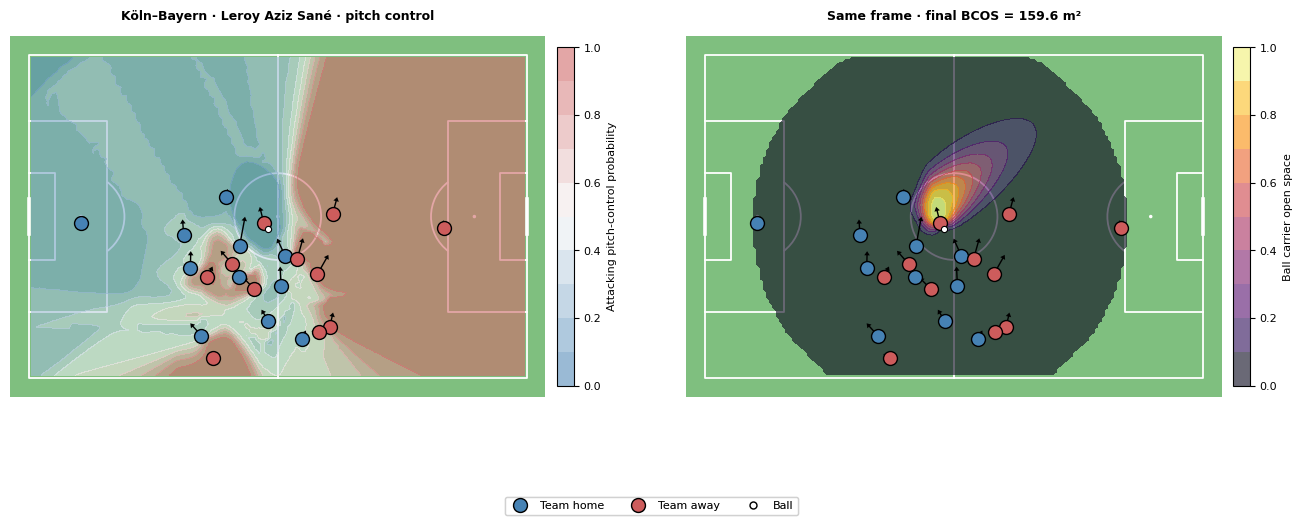

In [6]:
from PRESS.spatial_features import BCOS

frame = frames[0]
# Optional descriptor requested for this plot, independently of classifier inference.
bcos_display = BCOS(press.tracking_data, ball_drive_model=press.ball_drive_model)
bcos_display.compute_bcos(frame)  # Final transport by default.
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
plot_pass_map(press, frame, field="pitch_control", ax=axes[0], show=False,
              title=f"Köln–Bayern · {name[selected.player_id]} · pitch control")
plot_bcos(bcos_display, frame, ax=axes[1], show=False,
          title=f"Same frame · final BCOS = {bcos_display.get_result(frame)['BCOS area']:.1f} m²")
plt.show()

In [7]:
fig, ax = plot_frame(
    press, int(selected.frame_receipt), show=False,
    title=f"Next control · {name[selected.target_pass]} · completed pass",
)
fig.savefig("figures/idsse_pavard_reception.png", dpi=170)
plt.close(fig)


![Benjamin Pavard controls the completed pass in the observed tracking frame.](../../figures/idsse_pavard_reception.png){width=65%}


## Outputs and reproducibility

The object holds copied tracking/annotations and separate numerical component caches. The input tables, alignment report and segmentation audit remain distinct from model outputs. Saving numerical results leaves the original IDSSE data at its source.

In [8]:
print("Stored result components:", list(press.get_results()))
print("BCOS classifier feature:", press.get_result_configuration(frame)["ACTION_SELECTION"]["BCOS feature formulation"])
press.player_possessions_data.to_parquet(output_dir / "possessions.parquet", index=False)
press.actions_data.to_parquet(output_dir / "actions.parquet", index=False)
(output_dir / "segmentation.json").write_text(json.dumps(report, indent=2))
press.save_results(output_dir / "results", overwrite=True)
print("Saved input annotations, audit, checkpoint table and numerical results.")

Stored result components: ['PPCF', 'BALL_DRIVE_RISK', 'ACTION_SELECTION', 'HAZARD', 'BCOS', 'RESIDUAL_RISK', 'XLOSS']
BCOS classifier feature: effective_hazard
Saved input annotations, audit, checkpoint table and numerical results.


## References and data credit

Data: Deutsche Fußball Liga (DFL), IDSSE, CC BY 4.0 [@bassek2025idsse; @idsse-repository]. Original data access and attribution instructions: [official IDSSE repository](https://github.com/spoho-datascience/idsse-data). Synchronization/control software: DataBallPy, MIT license [@oonk2026databallpy; @databallpy-repository].